# 01 · Diffusion vs flow matching on 2D toy data

Both methods learn to turn Gaussian noise into samples from a data distribution. On 2D data
we can *see* what they do: the paths each particle follows, and how many steps are needed.

| | Diffusion (DDPM) | Flow matching |
|---|---|---|
| Path noise → data | reverse of a noising **SDE** | **ODE** along (nearly) straight lines |
| Network predicts | noise $\varepsilon$ (≈ score $\nabla \log p_t$) | velocity $v = x_1 - x_0$ |
| Loss | $\lVert \varepsilon - \varepsilon_\theta(x_t, t)\rVert^2$ | $\lVert (x_1 - x_0) - v_\theta(x_t, t)\rVert^2$ |
| Sampling | DDPM (1000 stochastic steps) or DDIM (deterministic, ~50) | Euler / RK2 on the ODE, 10–50 steps |

We train **the same MLP** with three objectives: diffusion, flow matching (FM) and
flow matching with minibatch optimal-transport pairing (OT-FM), and compare them.

In [1]:
import time
import matplotlib.pyplot as plt
import torch

from dfm import MLP, Diffusion, FlowMatching, train
from dfm.data import loader_2d, sample_2d
from dfm import viz

torch.manual_seed(0)
device = "cpu"
plt.rcParams["figure.dpi"] = 110

## 1. The target distributions

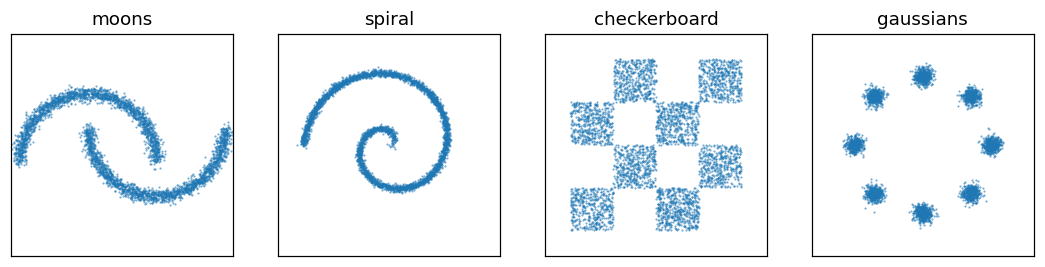

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, name in zip(axes, ["moons", "spiral", "checkerboard", "gaussians"]):
    viz.scatter(ax, sample_2d(name, 4000), title=name)
plt.show()

## 2. Training

Same network (residual MLP, ~0.3M parameters), same optimiser and number of steps; only
the loss changes. Change `DATASET` to try the other distributions.

In [3]:
DATASET = "moons"
STEPS = 4000
loader = loader_2d(DATASET, batch_size=512)

methods = {
    "Diffusion": Diffusion(num_steps=1000, schedule="cosine"),
    "FM": FlowMatching(ot=False),
    "OT-FM": FlowMatching(ot=True),
}
models, losses = {}, {}
for name, method in methods.items():
    t0 = time.time()
    models[name], losses[name] = train(MLP(), method, loader, steps=STEPS, lr=1e-3, device=device)
    print(f"{name}: {time.time() - t0:.0f}s")

  0%|          | 0/4000 [00:00<?, ?it/s]

Diffusion: 53s


  0%|          | 0/4000 [00:00<?, ?it/s]

FM: 50s


  0%|          | 0/4000 [00:00<?, ?it/s]

OT-FM: 200s


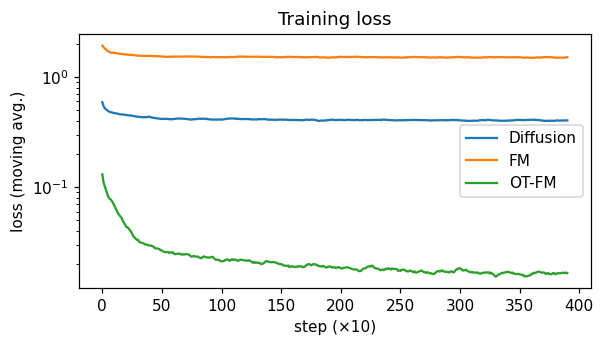

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
for name, l in losses.items():
    ax.plot(torch.tensor(l).unfold(0, 100, 10).mean(1), label=name)
ax.set(yscale="log", xlabel="step (×10)", ylabel="loss (moving avg.)", title="Training loss")
ax.legend(); plt.show()

The losses are not comparable in absolute value (they regress different targets), but
they show that all three trainings converge.

## 3. Samples and trajectories

DDPM simulates the reverse SDE: paths are noisy and wander. DDIM follows the
*probability-flow ODE* of the same diffusion model: smooth but curved. Flow matching
follows its learned ODE, and OT pairing makes the paths almost straight.

**Note on DDIM.** Each DDIM step first predicts the clean point $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$. Near pure noise $\bar\alpha_t \approx 0$, so tiny errors in $\hat\varepsilon$ explode. As in 🤗 diffusers, we clip $\hat x_0$ to the range of the data.

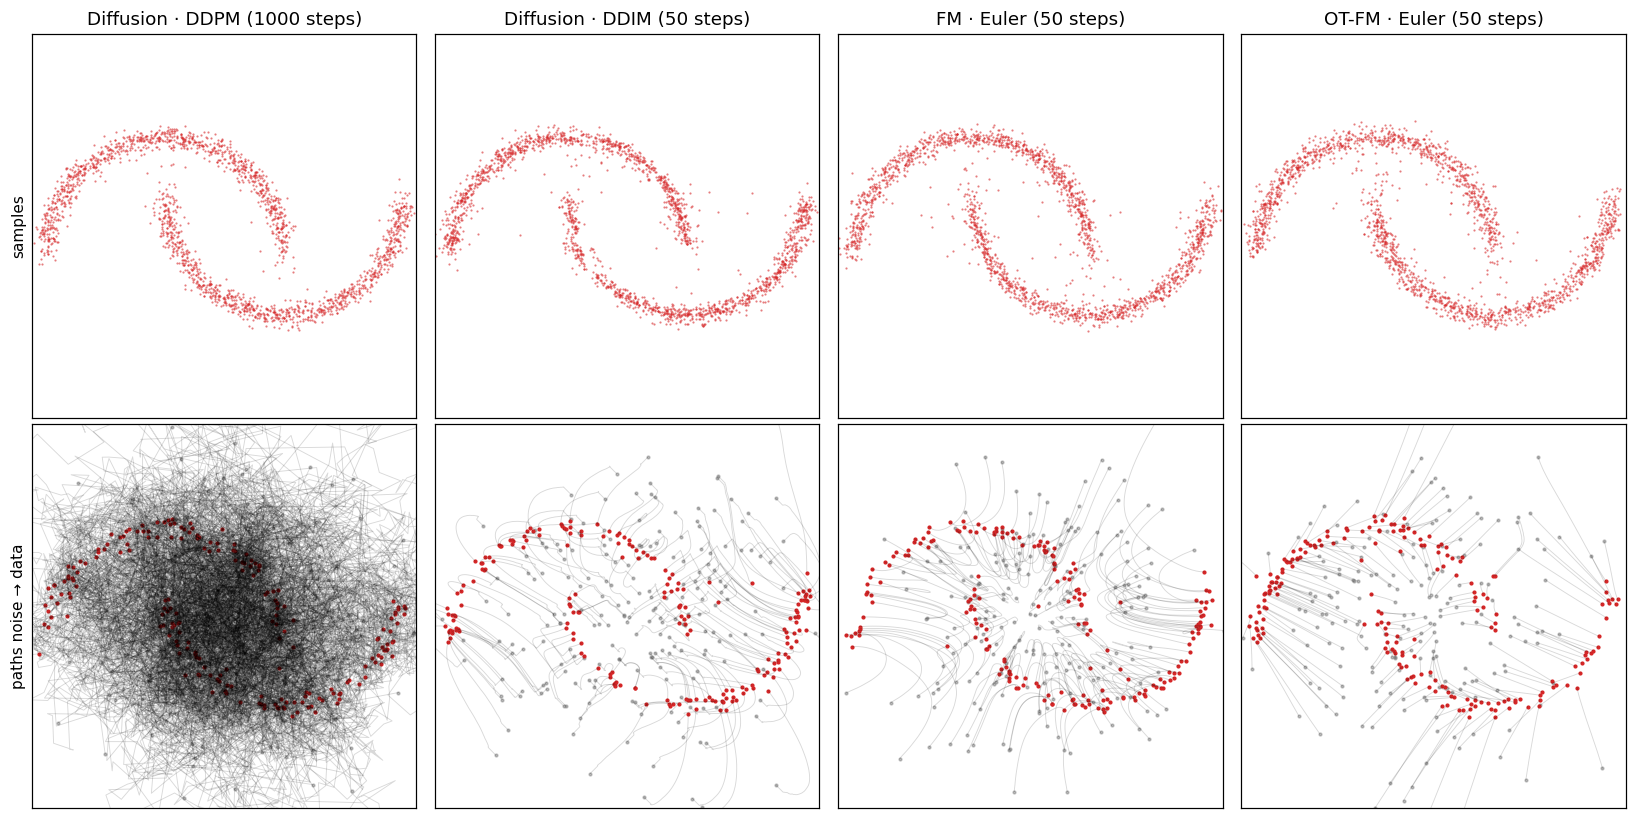

In [5]:
N = 2000
CLIP = 3.0  # DDIM: clip the predicted clean point x0 to the data range
torch.manual_seed(1)
samplers = {
    "Diffusion · DDPM (1000 steps)": lambda: methods["Diffusion"].sample_ddpm(models["Diffusion"], (N, 2), keep=100),
    "Diffusion · DDIM (50 steps)": lambda: methods["Diffusion"].sample_ddim(models["Diffusion"], (N, 2), steps=50, keep=50, clip=CLIP),
    "FM · Euler (50 steps)": lambda: methods["FM"].sample(models["FM"], (N, 2), steps=50, keep=50),
    "OT-FM · Euler (50 steps)": lambda: methods["OT-FM"].sample(models["OT-FM"], (N, 2), steps=50, keep=50),
}
results = {name: f() for name, f in samplers.items()}

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for col, (name, (x, traj)) in enumerate(results.items()):
    viz.scatter(axes[0, col], x, title=name, color="C3")
    viz.trajectories(axes[1, col], traj, n=200)
axes[0, 0].set_ylabel("samples"); axes[1, 0].set_ylabel("paths noise → data")
plt.tight_layout(); plt.show()

## 4. How many steps do we really need?

We measure sample quality with the **sliced Wasserstein distance** (SWD) to fresh data:
project both point clouds on random directions and average the 1D Wasserstein distances.
Lower is better. The dashed line is the SWD between two independent data samples (the
best achievable).

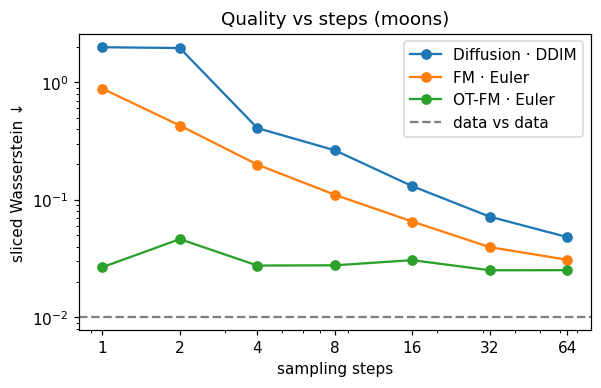

In [6]:
def sliced_wasserstein(x, y, n_proj=500):
    theta = torch.randn(2, n_proj)
    theta = theta / theta.norm(dim=0)
    px, _ = torch.sort(x @ theta, dim=0)
    py, _ = torch.sort(y @ theta, dim=0)
    return (px - py).abs().mean().item()

ref = sample_2d(DATASET, N)
floor = sliced_wasserstein(sample_2d(DATASET, N), ref)
step_grid = [1, 2, 4, 8, 16, 32, 64]
torch.manual_seed(2)
swd = {
    "Diffusion · DDIM": [sliced_wasserstein(methods["Diffusion"].sample_ddim(models["Diffusion"], (N, 2), steps=s, clip=CLIP), ref) for s in step_grid],
    "FM · Euler": [sliced_wasserstein(methods["FM"].sample(models["FM"], (N, 2), steps=s), ref) for s in step_grid],
    "OT-FM · Euler": [sliced_wasserstein(methods["OT-FM"].sample(models["OT-FM"], (N, 2), steps=s), ref) for s in step_grid],
}
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, v in swd.items():
    ax.plot(step_grid, v, "o-", label=name)
ax.axhline(floor, ls="--", c="grey", label="data vs data")
ax.set(xscale="log", yscale="log", xlabel="sampling steps", ylabel="sliced Wasserstein ↓", title=f"Quality vs steps ({DATASET})")
ax.set_xticks(step_grid, step_grid); ax.legend(); plt.show()

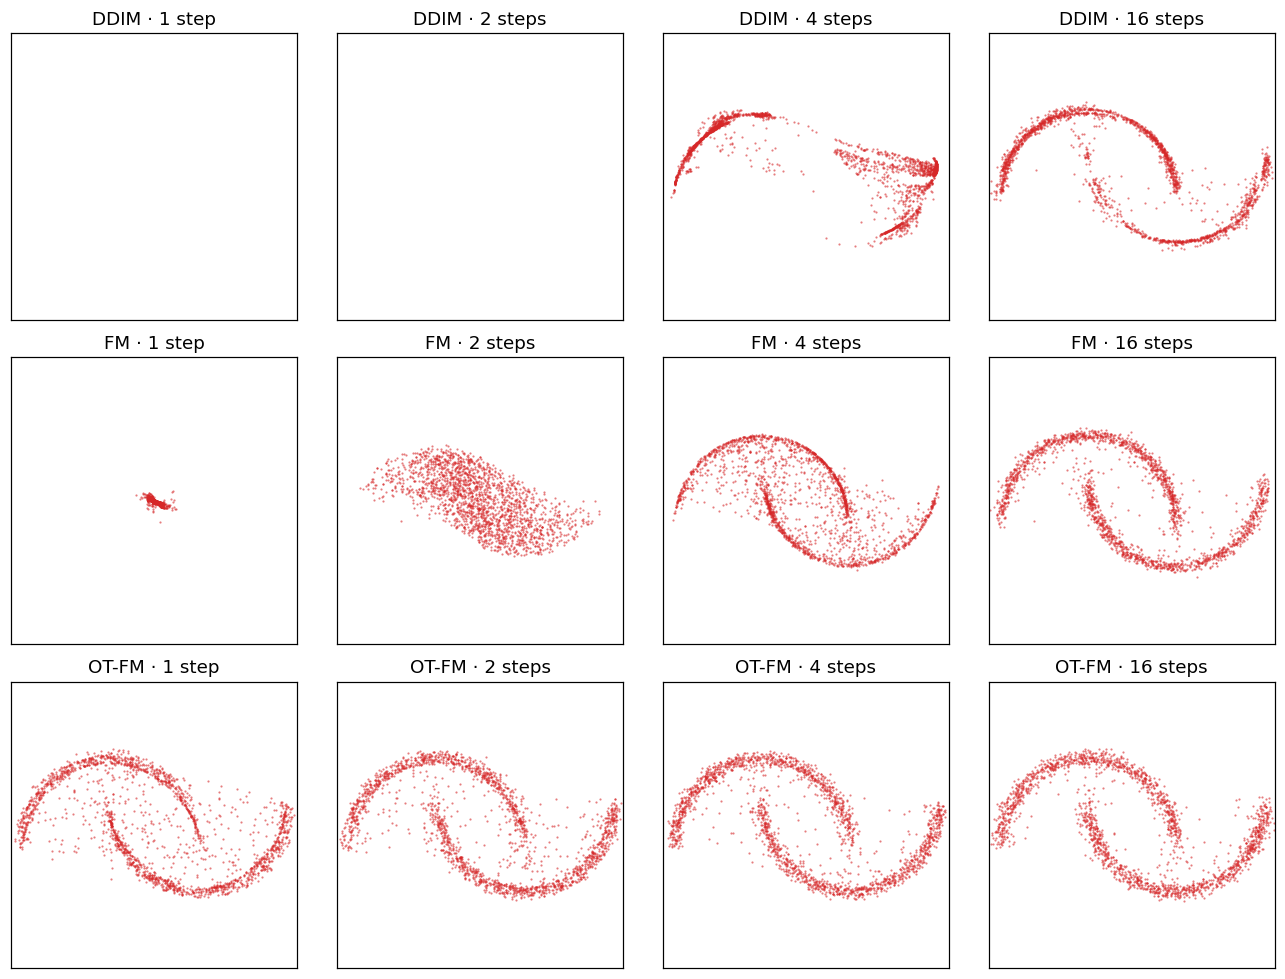

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
torch.manual_seed(3)
rows = {
    "DDIM": lambda s: methods["Diffusion"].sample_ddim(models["Diffusion"], (N, 2), steps=s, clip=CLIP),
    "FM": lambda s: methods["FM"].sample(models["FM"], (N, 2), steps=s),
    "OT-FM": lambda s: methods["OT-FM"].sample(models["OT-FM"], (N, 2), steps=s),
}
for r, (name, f) in enumerate(rows.items()):
    for c, s in enumerate([1, 2, 4, 16]):
        viz.scatter(axes[r, c], f(s), title=f"{name} · {s} step{'s' if s > 1 else ''}", color="C3")
plt.tight_layout(); plt.show()

## 5. How straight are the paths?

For each particle we compare the length of its path with the straight distance between
start and end. A ratio of 1 means a perfectly straight path, which is what optimal
transport would give and why few steps suffice.

In [8]:
def straightness(traj):
    path = torch.stack(traj)              # (time, N, 2)
    length = (path[1:] - path[:-1]).norm(dim=-1).sum(0)
    chord = (path[-1] - path[0]).norm(dim=-1)
    return (length / chord).median().item()

for name, (_, traj) in results.items():
    print(f"{name:32s} path length / straight distance = {straightness(traj):.2f}")

Diffusion · DDPM (1000 steps)    path length / straight distance = 15.80
Diffusion · DDIM (50 steps)      path length / straight distance = 1.27
FM · Euler (50 steps)            path length / straight distance = 1.67
OT-FM · Euler (50 steps)         path length / straight distance = 1.00


## Takeaways (moons, 4000 training steps, CPU)

- **All four samplers learn the distribution** with enough steps (DDPM with 1000, the others with 50).
- **DDPM** paths are random walks (path length ≈ 16× the straight distance): the reverse SDE re-injects noise at every step, so it needs hundreds of steps.
- **DDIM** reuses the *same* diffusion network as a deterministic ODE and works well with ~50 steps. Its paths are fairly smooth (ratio 1.27), yet it degrades quickly below ~16 steps: most of the curvature is concentrated near pure noise, where $\bar\alpha_t \approx 0$ and the predicted $\hat x_0$ has to be clipped (with 1–2 steps all samples end up on the clipping boundary, outside the plot).
- **Flow matching** reaches better quality than DDIM at every number of steps, although with 1 step it collapses to the mean: a single Euler step only follows the *average* velocity.
- **OT-FM** gives perfectly straight paths (ratio 1.00) and **already matches the distribution with a single step** — the practical payoff of the link with optimal transport, and the idea behind rectified flow and one-step generators. The price: minibatch OT makes training ~4.5× slower here (the assignment problem is solved on the CPU at every step).

Next: the same comparison on colour images (`02_butterflies.ipynb`).